# Student Performance Prediction Using Machine Learning

**Problem statement:** Predict a student's academic Performance Index (0–100) using study habits and academic/lifestyle factors.

## Project objectives
- Explore factors associated with student performance.
- Prepare data for machine learning.
- Train and compare regression models.
- Evaluate predictions using MAE, RMSE and R².
- Predict the performance index for a sample student.

## Dataset note
This ready-to-view notebook uses a **simulated teaching dataset of 1,000 student records** generated with a fixed random seed. It works offline and includes saved outputs. It is **not** the original Kaggle dataset and must not be described as real student survey data. Results demonstrate the ML workflow only.

## 1. Import libraries

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
print("All libraries imported successfully.")

All libraries imported successfully.


## 2. Create and load the dataset

In [2]:
# Reproducible simulated dataset (no upload or internet connection needed)
rng = np.random.default_rng(42)
n = 1000
hours_studied = rng.integers(1, 10, n)
previous_scores = rng.integers(40, 101, n)
extracurricular = rng.choice(["Yes", "No"], n, p=[0.45, 0.55])
sleep_hours = rng.integers(4, 10, n)
sample_papers = rng.integers(0, 10, n)
extra_effect = (extracurricular == "Yes").astype(int) * 2.0
noise = rng.normal(0, 5, n)
performance = 8 + 2.6*hours_studied + 0.55*previous_scores + 1.1*sleep_hours + 0.8*sample_papers + extra_effect + noise
performance = np.clip(performance, 0, 100)

df = pd.DataFrame({
    "Hours Studied": hours_studied,
    "Previous Scores": previous_scores,
    "Extracurricular Activities": extracurricular,
    "Sleep Hours": sleep_hours,
    "Sample Question Papers Practiced": sample_papers,
    "Performance Index": np.round(performance, 1)
})
print("Dataset generated successfully.")
print("Dataset shape:", df.shape)
display(df.head())

Dataset generated successfully.
Dataset shape: (1000, 6)


,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,1,89,Yes,5,1,73.1
1,7,84,No,9,0,78.5
2,6,74,Yes,4,6,61.8
3,4,94,Yes,6,6,74.7
4,4,47,No,8,7,65.8


## 3. Understand the dataset

In [3]:
print("Column names:")
print(df.columns.tolist())
print("\\nDataset information:")
df.info()
print("\\nStatistical summary:")
display(df.describe().round(2))

Column names:
['Hours Studied', 'Previous Scores', 'Extracurricular Activities', 'Sleep Hours', 'Sample Question Papers Practiced', 'Performance Index']
\nDataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 6 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Hours Studied                     1000 non-null   int64  
 1   Previous Scores                   1000 non-null   int64  
 2   Extracurricular Activities        1000 non-null   object 
 3   Sleep Hours                       1000 non-null   int64  
 4   Sample Question Papers Practiced  1000 non-null   int64  
 5   Performance Index                 1000 non-null   float64
dtypes: float64(1), int64(4), object(1)
memory usage: 47.0+ KB
\nStatistical summary:


,Hours Studied,Previous Scores,Sleep Hours,Sample Question Papers Practiced,Performance Index
count,1000.00,1000.00,1000.00,1000.00,1000.00
mean,5.03,69.81,6.44,4.51,71.09
std,2.59,17.78,1.73,2.83,12.90
min,1.00,40.00,4.00,0.00,35.00
25%,3.00,55.00,5.00,2.00,61.80
50%,5.00,70.00,6.00,5.00,70.90
75%,7.00,85.00,8.00,7.00,79.93
max,9.00,100.00,9.00,9.00,100.00


## 4. Data cleaning

In [4]:
print("Missing values:")
display(df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates().copy()
for col in df.select_dtypes(include=np.number).columns:
    df[col] = df[col].fillna(df[col].median())
for col in df.select_dtypes(exclude=np.number).columns:
    df[col] = df[col].fillna(df[col].mode()[0])
print("Data cleaning completed.")
print("Shape after cleaning:", df.shape)

Missing values:


Hours Studied                       0
Previous Scores                     0
Extracurricular Activities          0
Sleep Hours                         0
Sample Question Papers Practiced    0
Performance Index                   0
dtype: int64

Duplicate rows: 0
Data cleaning completed.
Shape after cleaning: (1000, 6)


## 5. Exploratory Data Analysis

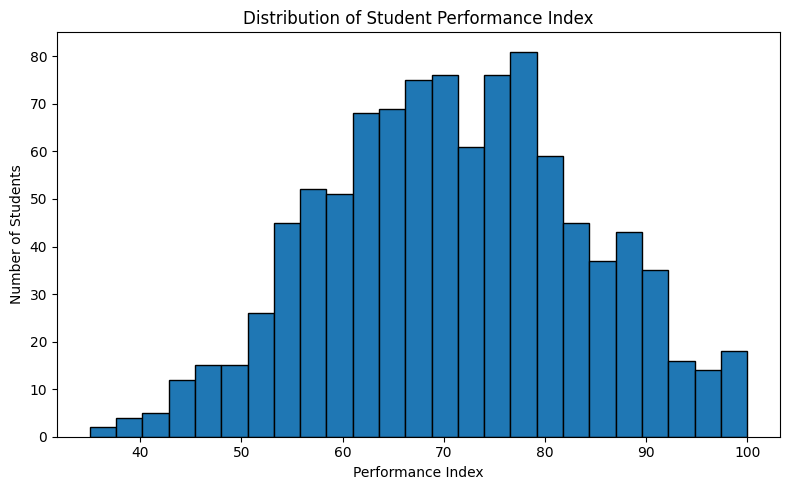

In [5]:
plt.figure(figsize=(8,5))
plt.hist(df["Performance Index"], bins=25, edgecolor="black")
plt.title("Distribution of Student Performance Index")
plt.xlabel("Performance Index")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.show()

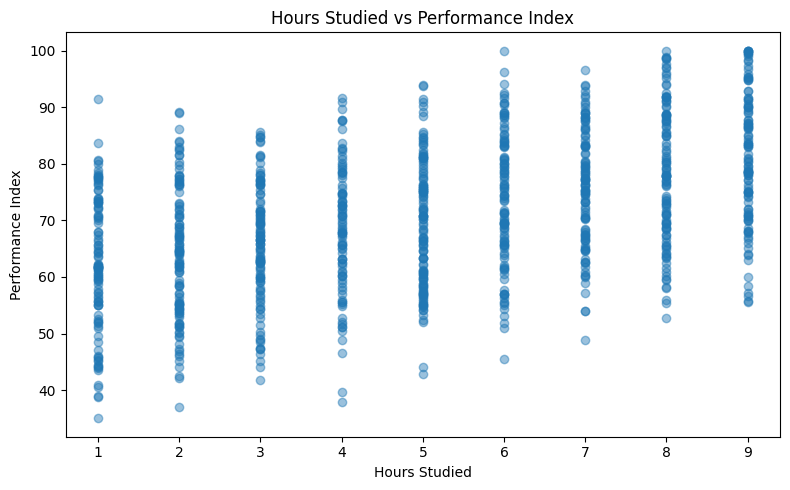

In [6]:
plt.figure(figsize=(8,5))
plt.scatter(df["Hours Studied"], df["Performance Index"], alpha=0.45)
plt.title("Hours Studied vs Performance Index")
plt.xlabel("Hours Studied")
plt.ylabel("Performance Index")
plt.tight_layout()
plt.show()

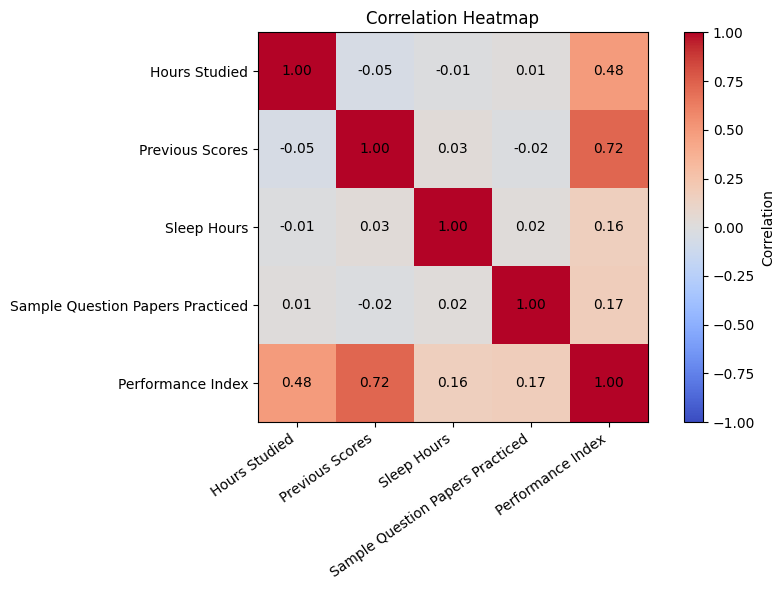

In [7]:
corr = df.select_dtypes(include=np.number).corr()
fig, ax = plt.subplots(figsize=(9,6))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr.columns)))
ax.set_yticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=35, ha="right")
ax.set_yticklabels(corr.columns)
for i in range(len(corr.columns)):
    for j in range(len(corr.columns)):
        ax.text(j, i, f"{corr.iloc[i,j]:.2f}", ha="center", va="center")
fig.colorbar(im, ax=ax, label="Correlation")
ax.set_title("Correlation Heatmap")
plt.tight_layout()
plt.show()

## 6. Split data into training and testing sets

In [8]:
target = "Performance Index"
X = df.drop(columns=[target])
y = df[target]
categorical_features = X.select_dtypes(include=["object", "category"]).columns.tolist()
numerical_features = X.select_dtypes(include=np.number).columns.tolist()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)
print("Input features:", X.columns.tolist())
print("Target variable:", target)
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Input features: ['Hours Studied', 'Previous Scores', 'Extracurricular Activities', 'Sleep Hours', 'Sample Question Papers Practiced']
Target variable: Performance Index
Training records: 800
Testing records: 200


## 7. Train machine learning models

In [9]:
preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numerical_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
])
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(max_depth=8, random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, max_depth=12, random_state=42, n_jobs=-1)
}
trained_models = {}
results = []
for name, estimator in models.items():
    pipeline = Pipeline([("preprocessor", preprocessor), ("model", estimator)])
    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)
    trained_models[name] = pipeline
    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2 Score": r2_score(y_test, predictions)
    })
results_df = pd.DataFrame(results).sort_values("R2 Score", ascending=False)
display(results_df.round(3))

,Model,MAE,RMSE,R2 Score
0,Linear Regression,4.106,5.233,0.842
2,Random Forest,4.647,5.690,0.813
1,Decision Tree,5.545,6.969,0.720


## 8. Compare model performance

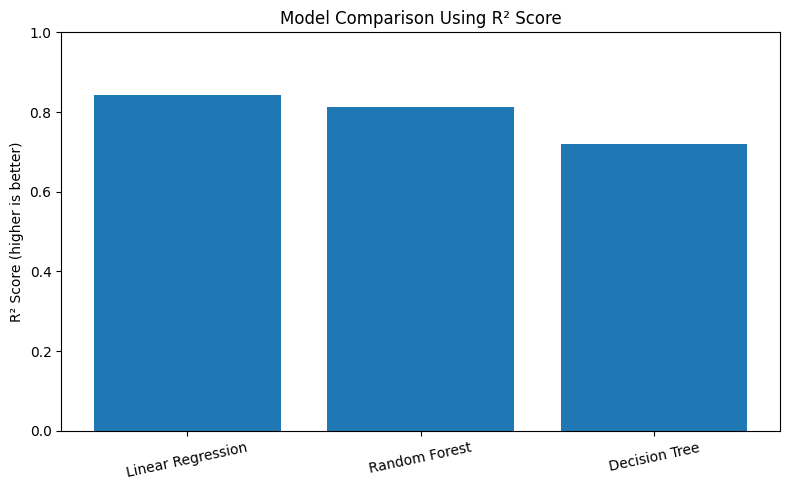

Best model based on test R² score: Linear Regression


In [10]:
plt.figure(figsize=(8,5))
plt.bar(results_df["Model"], results_df["R2 Score"])
plt.title("Model Comparison Using R² Score")
plt.ylabel("R² Score (higher is better)")
plt.ylim(0,1)
plt.xticks(rotation=12)
plt.tight_layout()
plt.show()
best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]
print("Best model based on test R² score:", best_model_name)

## 9. Actual vs predicted values

,Actual Performance Index,Predicted Performance Index
0,79.8,72.09
1,61.9,59.48
2,68.5,78.40
3,69.4,67.07
4,60.1,67.27
5,82.5,86.08
6,65.1,69.56
7,76.0,77.75
8,88.7,90.45
9,78.7,82.59


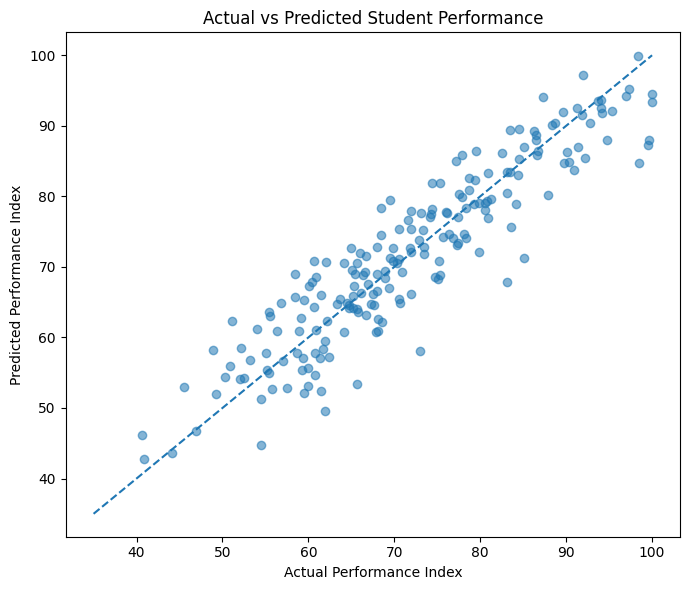

In [11]:
best_predictions = best_model.predict(X_test)
comparison = pd.DataFrame({
    "Actual Performance Index": y_test.values,
    "Predicted Performance Index": best_predictions
})
display(comparison.head(10).round(2))
plt.figure(figsize=(7,6))
plt.scatter(y_test, best_predictions, alpha=0.55)
plt.xlabel("Actual Performance Index")
plt.ylabel("Predicted Performance Index")
plt.title("Actual vs Predicted Student Performance")
low = min(y.min(), best_predictions.min())
high = max(y.max(), best_predictions.max())
plt.plot([low,high],[low,high],linestyle="--")
plt.tight_layout()
plt.show()

## 10. Evaluate the selected model

In [12]:
mae = mean_absolute_error(y_test, best_predictions)
rmse = np.sqrt(mean_squared_error(y_test, best_predictions))
r2 = r2_score(y_test, best_predictions)
print("Selected model:", best_model_name)
print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"R² Score: {r2:.3f}")
print(f"Explained variance percentage (R² × 100): {r2*100:.1f}%")

Selected model: Linear Regression
Mean Absolute Error (MAE): 4.11
Root Mean Squared Error (RMSE): 5.23
R² Score: 0.842
Explained variance percentage (R² × 100): 84.2%


## 11. Predict performance for a new student

In [13]:
new_student = pd.DataFrame([{
    "Hours Studied": 6,
    "Previous Scores": 75,
    "Extracurricular Activities": "Yes",
    "Sleep Hours": 7,
    "Sample Question Papers Practiced": 5
}])
predicted_score = float(np.clip(best_model.predict(new_student)[0], 0, 100))
if predicted_score >= 75:
    category = "High"
elif predicted_score >= 50:
    category = "Moderate"
else:
    category = "Needs support"
print("New student details:")
display(new_student)
print(f"Predicted Performance Index: {predicted_score:.2f} / 100")
print("Predicted performance category:", category)

New student details:


,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced
0,6,75,Yes,7,5


Predicted Performance Index: 78.53 / 100
Predicted performance category: High


## 12. Conclusion

A complete machine learning workflow was implemented to estimate a student's Performance Index from study hours, previous scores, extracurricular participation, sleep hours and practice-question activity.

Linear Regression, Decision Tree and Random Forest were trained and compared using MAE, RMSE and R². The model with the highest test R² score was selected.

**Limitations:** The dataset is simulated for demonstration. Predictions are estimates, not guaranteed exam marks, and should not be used alone for high-stakes decisions about students.

**References:** Scikit-learn documentation (https://scikit-learn.org/stable/), Pandas documentation (https://pandas.pydata.org/docs/), Matplotlib documentation (https://matplotlib.org/stable/).